# MSCM-net: Indian Pines experiments
Run **Cell 1 and Cell 2 first** after every reconnect, then any experiment cell. Finished seeds are saved to Drive and skipped, so every cell can be re-run safely.

Runtime must be **GPU** (Runtime → Change runtime type → T4).

## Cell 1: mount Drive and check files

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os
sys.path.append('/content/drive/MyDrive/MSCMnet/codes')
print(sorted(os.listdir('/content/drive/MyDrive/MSCMnet/codes')))
# expect: experiments.py, hsi_data.py, mscm_modules.py, mscm_net.py, train.py

Mounted at /content/drive
['__pycache__', 'experiments.py', 'figures.py', 'hsi_data.py', 'mscm_modules.py', 'mscm_net.py', 'train.py']


## Cell 2: load code and set paths (reloads every module)

In [3]:
import sys, importlib, torch
sys.path.append('/content/drive/MyDrive/MSCMnet/codes')
sys.path_importer_cache.clear()

import hsi_data, mscm_modules, mscm_net, train, experiments
for m in (hsi_data, mscm_modules, mscm_net, train, experiments):
    importlib.reload(m)

R = '/content/drive/MyDrive/MSCMnet'
D = f'{R}/data/Indian_Pines'
data, gt = f'{D}/indian_pines_data.mat', f'{D}/indian_pines_gt.mat'

print('GPU available:', torch.cuda.is_available())
print('data files found:', os.path.exists(data), os.path.exists(gt))

GPU available: True
data files found: True True


## Baseline summary (10 seeds already done)

In [ ]:
import glob, numpy as np
def summary(tag):
    rs = [np.load(f) for f in sorted(glob.glob(f'{R}/results/{tag}_seed*.npz'))]
    for k in ('OA', 'AA', 'Kappa'):
        v = np.array([float(r[k]) for r in rs])
        print(f'{tag:12s} {k:6s} {v.mean():.2f} ± {v.std():.2f}   (min {v.min():.2f}, max {v.max():.2f}, n={len(v)})')

summary('indian_pines')

indian_pines OA     88.82 ± 2.86   (min 83.40, max 92.30, n=10)
indian_pines AA     94.43 ± 1.30   (min 91.93, max 95.87, n=10)
indian_pines Kappa  87.29 ± 3.22   (min 81.18, max 91.21, n=10)


## Experiment 1: dropout 0.3 (about 26 min)

In [ ]:
experiments.run_config('ip_drop03', data, gt, R, dropout=0.3)
experiments.compare(R, 'ip_drop03')

[ip_drop03] seed 0 done, skipping
[ip_drop03] seed 1 done, skipping
[ip_drop03] seed 2 done, skipping
[ip_drop03] seed 3 done, skipping
[ip_drop03] seed 4 done, skipping
[ip_drop03] seed 5 done, skipping
indian_pines seed=6 device=cuda classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.6052  train_acc 21.2%  [3s]
ep  10  loss 0.3192  train_acc 98.2%  [16s]
ep  20  loss 0.0615  train_acc 99.8%  [31s]
ep  30  loss 0.0281  train_acc 100.0%  [45s]
ep  40  loss 0.0179  train_acc 100.0%  [60s]
ep  50  loss 0.0097  train_acc 100.0%  [75s]
ep  60  loss 0.0073  train_acc 100.0%  [89s]
ep  70  loss 0.0057  train_acc 100.0%  [104s]
ep  80  loss 0.0047  train_acc 100.0%  [119s]
ep  90  loss 0.0033  train_acc 100.0%  [133s]
ep 100  loss 0.0028  train_acc 100.0%  [148s]
RESULT indian_pines seed=6: OA 93.92  AA 97.01  Kappa 93.06
indian_pines seed=7 device=cuda classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.6978  train_acc 13.3%  [1s]
ep  10  loss 0.2997  train_acc 98.6%  [15s

## Experiment 2: data augmentation (flips and 90° rotations)

In [ ]:
experiments.run_config('ip_aug', data, gt, R, augment=True)
experiments.compare(R, 'ip_aug')

indian_pines seed=0 device=cuda classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.4869  train_acc 25.2%  [2s]
ep  10  loss 0.2502  train_acc 97.7%  [15s]
ep  20  loss 0.0536  train_acc 99.8%  [30s]
ep  30  loss 0.0235  train_acc 100.0%  [46s]
ep  40  loss 0.0128  train_acc 100.0%  [61s]
ep  50  loss 0.0076  train_acc 100.0%  [76s]
ep  60  loss 0.0043  train_acc 100.0%  [91s]
ep  70  loss 0.0172  train_acc 99.5%  [106s]
ep  80  loss 0.0178  train_acc 99.8%  [122s]
ep  90  loss 0.0135  train_acc 99.8%  [137s]
ep 100  loss 0.0032  train_acc 100.0%  [152s]
RESULT indian_pines seed=0: OA 92.31  AA 96.49  Kappa 91.25
indian_pines seed=1 device=cuda classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.4010  train_acc 30.4%  [2s]
ep  10  loss 0.2536  train_acc 96.4%  [15s]
ep  20  loss 0.0663  train_acc 99.3%  [30s]
ep  30  loss 0.0368  train_acc 99.8%  [46s]
ep  40  loss 0.0115  train_acc 100.0%  [61s]
ep  50  loss 0.0065  train_acc 100.0%  [76s]
ep  60  loss 0.0047  train_

## Experiment 3: weight decay 1e-4

In [ ]:
experiments.run_config('ip_wd', data, gt, R, weight_decay=1e-4)
experiments.compare(R, 'ip_wd')

indian_pines seed=0 device=cuda classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.4819  train_acc 24.5%  [2s]
ep  10  loss 0.1193  train_acc 100.0%  [15s]
ep  20  loss 0.0268  train_acc 100.0%  [30s]
ep  30  loss 0.0138  train_acc 100.0%  [45s]
ep  40  loss 0.0085  train_acc 100.0%  [60s]
ep  50  loss 0.0061  train_acc 100.0%  [75s]
ep  60  loss 0.0047  train_acc 100.0%  [90s]
ep  70  loss 0.0034  train_acc 100.0%  [105s]
ep  80  loss 0.0033  train_acc 100.0%  [120s]
ep  90  loss 0.0027  train_acc 100.0%  [135s]
ep 100  loss 0.0024  train_acc 100.0%  [150s]
RESULT indian_pines seed=0: OA 89.20  AA 95.09  Kappa 87.74
indian_pines seed=1 device=cuda classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.4016  train_acc 30.6%  [1s]
ep  10  loss 0.1070  train_acc 100.0%  [15s]
ep  20  loss 0.0273  train_acc 100.0%  [30s]
ep  30  loss 0.0132  train_acc 100.0%  [45s]
ep  40  loss 0.0085  train_acc 100.0%  [60s]
ep  50  loss 0.0056  train_acc 100.0%  [75s]
ep  60  loss 0.0050

## Show all comparisons so far (no training, just reads saved results)

In [ ]:
for tag in ('ip_drop03', 'ip_aug', 'ip_wd'):
    if glob.glob(f'{R}/results/{tag}_seed*.npz'):
        experiments.compare(R, tag); print()

NameError: name 'glob' is not defined

In [ ]:
experiments.run_config('ip_aug_drop03', data, gt, R, augment=True, dropout=0.3)
experiments.compare(R, 'ip_aug_drop03', baseline='ip_aug')

[ip_aug_drop03] seed 0 done, skipping
[ip_aug_drop03] seed 1 done, skipping
[ip_aug_drop03] seed 2 done, skipping
[ip_aug_drop03] seed 3 done, skipping
[ip_aug_drop03] seed 4 done, skipping
[ip_aug_drop03] seed 5 done, skipping
[ip_aug_drop03] seed 6 done, skipping
[ip_aug_drop03] seed 7 done, skipping
indian_pines seed=8 device=cpu classes=16 train=444 test=9805 params=578,140
ep   1  loss 2.5985  train_acc 20.0%  [45s]
ep  10  loss 0.4452  train_acc 90.8%  [470s]
ep  20  loss 0.1141  train_acc 98.6%  [963s]
ep  30  loss 0.0645  train_acc 98.9%  [1409s]
ep  40  loss 0.0369  train_acc 99.3%  [1862s]
ep  50  loss 0.0258  train_acc 99.8%  [2334s]
ep  60  loss 0.0109  train_acc 100.0%  [2814s]
ep  70  loss 0.0084  train_acc 100.0%  [3294s]


In [ ]:
experiments.compare(R, 'ip_aug_drop03')   # vs the original baseline

OA     ip_aug_drop03: 93.52 ± 1.55   baseline: 88.82 ± 2.86   diff +4.71 (sd of diff 3.27, better on 10/10 seeds)
AA     ip_aug_drop03: 96.74 ± 0.74   baseline: 94.43 ± 1.30   diff +2.32 (sd of diff 1.43, better on 10/10 seeds)
Kappa  ip_aug_drop03: 92.61 ± 1.75   baseline: 87.29 ± 3.22   diff +5.33 (sd of diff 3.67, better on 10/10 seeds)


In [ ]:
import glob
print(len(glob.glob(f'{R}/results/ip_aug_drop03_seed*.npz')), 'result files')

10 result files


In [ ]:
experiments.compare(R, 'ip_aug_drop03', baseline='ip_aug')

OA     ip_aug_drop03: 93.52 ± 1.55   baseline: 93.16 ± 1.13   diff +0.36 (sd of diff 1.39, better on 6/10 seeds)
AA     ip_aug_drop03: 96.74 ± 0.74   baseline: 96.67 ± 0.51   diff +0.08 (sd of diff 0.69, better on 7/10 seeds)
Kappa  ip_aug_drop03: 92.61 ± 1.75   baseline: 92.20 ± 1.28   diff +0.42 (sd of diff 1.57, better on 7/10 seeds)


using ip_aug seed 7 (OA 92.92; mean over seeds 93.16)
test OA 92.92  AA 96.62  Kappa 91.93


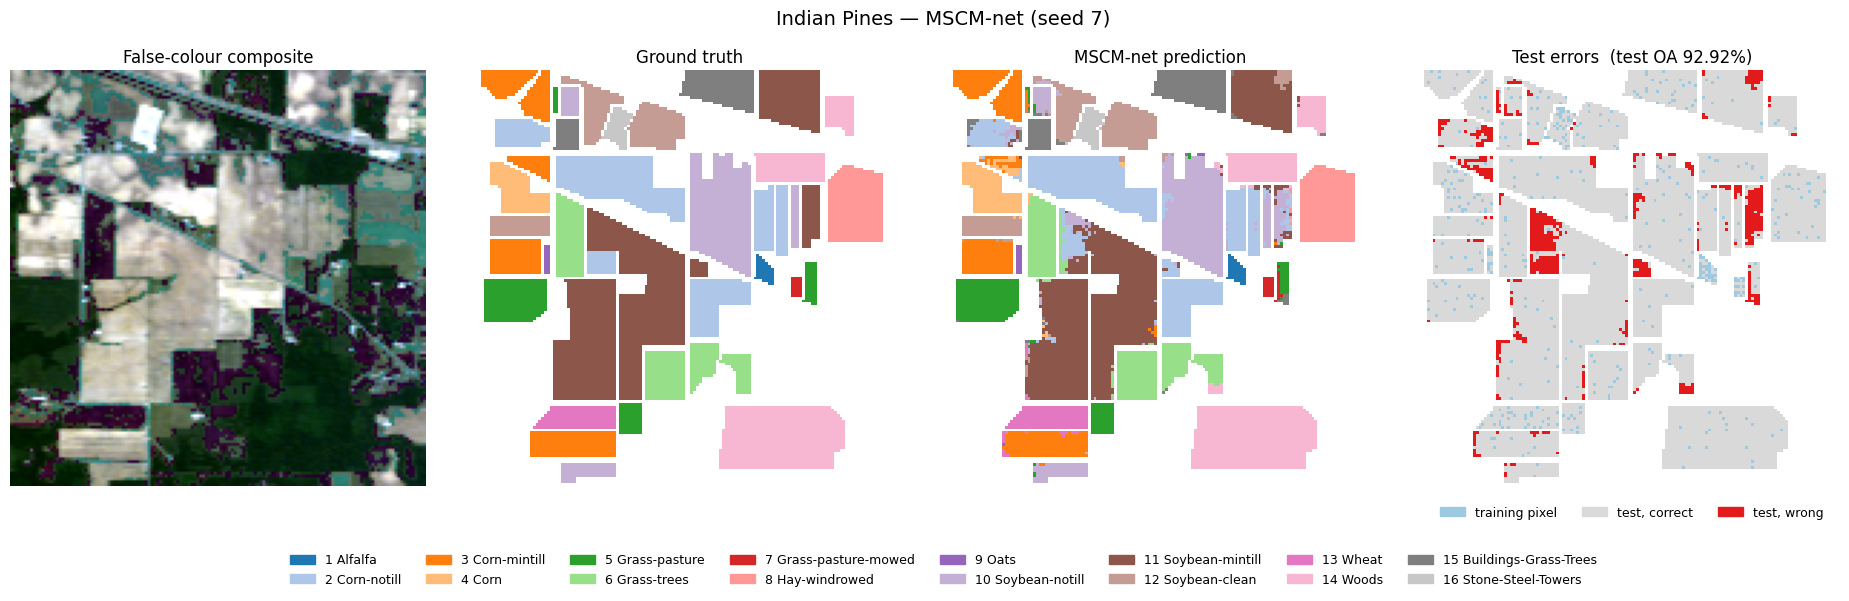

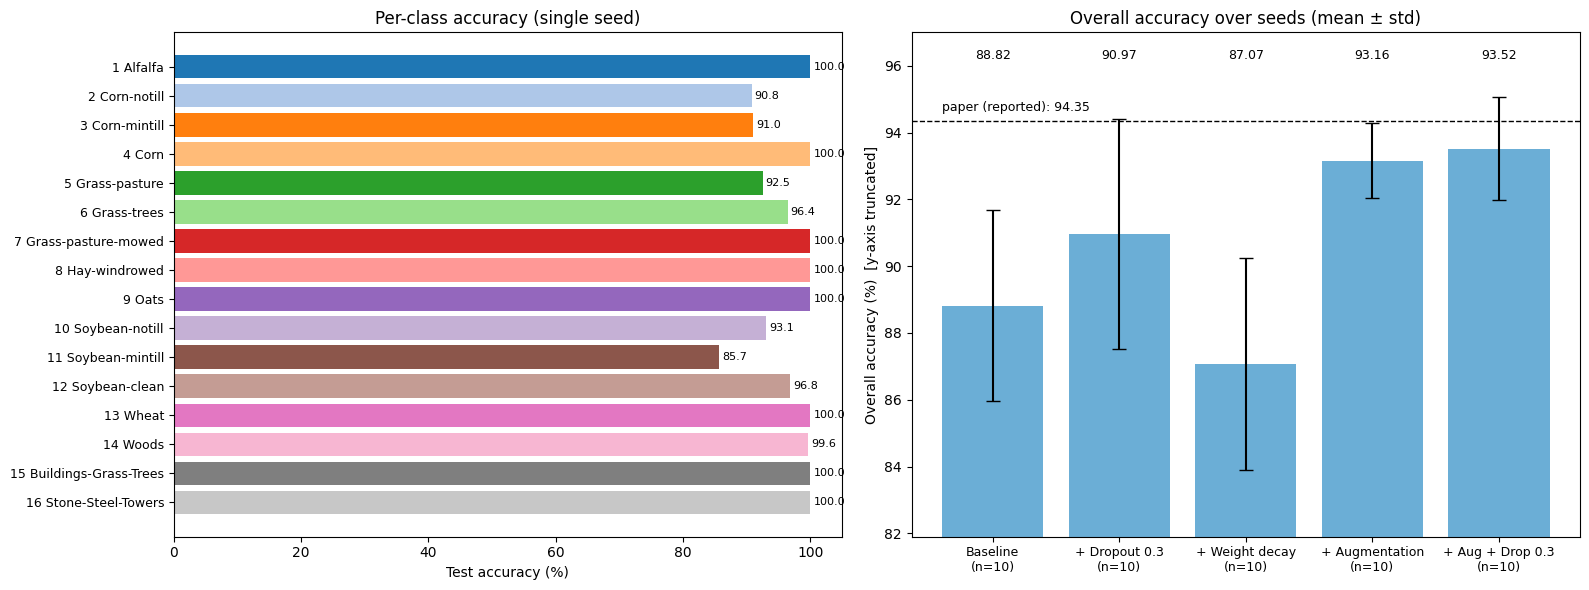

saved to /content/drive/MyDrive/MSCMnet/results/figures


In [5]:
import importlib, figures
importlib.reload(figures)
figures.make_figures(R, data, gt, tag='ip_aug')